<a href="https://colab.research.google.com/github/mohammeddyyan/Deep-learning/blob/main/Copy_of_Untitled5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
!pip install captum shap lime scikit-image grad-cam --quiet
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

# Captum for attributions (Integrated Gradients, Occlusion, GuidedBackprop)
from captum.attr import IntegratedGradients, Occlusion, GuidedBackprop

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 25.1 MB/s eta 0:00:00


device(type='cuda')

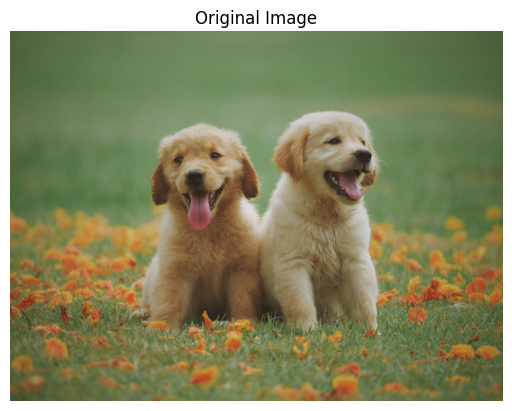

In [4]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

IMAGE_URL =   "https://images.pexels.com/photos/1108099/pexels-photo-1108099.jpeg"
response = requests.get(IMAGE_URL)
img_pil = Image.open(BytesIO(response.content)).convert("RGB")

# Using the local image file you provided - commented out due to FileNotFoundError
# image_path = "/content/vertical-shot-flowers-with-red-yellow-petals.jpg"
# img_pil = Image.open(image_path).convert("RGB")

plt.imshow(img_pil)
plt.axis("off")
plt.title("Original Image")
plt.show()

In [5]:
import requests
import json
import torch
import torchvision.models as models
import torchvision.transforms as transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define the preprocessing steps
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load a pre-trained model
model = models.resnet50(pretrained=True)
model.eval() # Set model to evaluation mode
model.to(device)

# Fetch ImageNet labels
IMAGENET_LABELS_URL = "https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json"
response = requests.get(IMAGENET_LABELS_URL)
imagenet_labels = json.loads(response.text)

def prepare_image(img_pil):
    input_tensor = preprocess(img_pil).unsqueeze(0).to(device)
    return input_tensor


def predict(input_tensor):
    with torch.no_grad():
        logits = model(input_tensor)

    probs = logits.softmax(dim=1)
    return probs, logits


input_tensor = prepare_image(img_pil)

probs, logits = predict(input_tensor)

top_prob, top_idx = probs.max(dim=1)

pred_label = imagenet_labels[top_idx.item()]

print(f"Top prediction: {pred_label} (prob={top_prob.item():.3f})")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s]


Top prediction: Golden Retriever (prob=0.887)


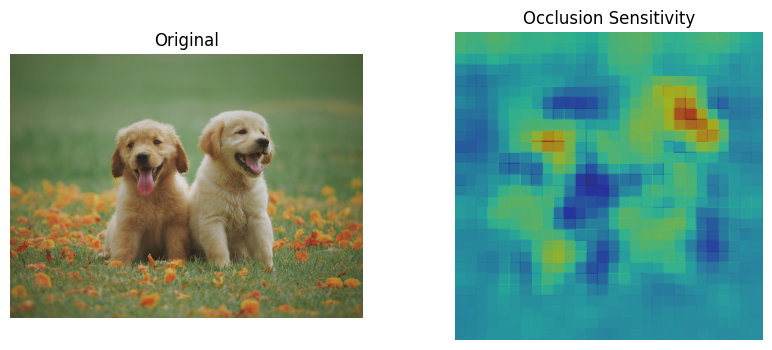

In [6]:
from captum.attr import Occlusion

occlusion = Occlusion(model)

input_tensor.requires_grad = False

target = top_idx.item()

attributions_occ = occlusion.attribute(
    input_tensor,
    strides=(1, 8, 8),
    target=target,
    sliding_window_shapes=(1, 15, 15),
    baselines=0
)

attr_occ = attributions_occ.squeeze().detach().cpu().numpy()
attr_occ = attr_occ.sum(axis=0)

attr_occ_norm = (
    attr_occ - attr_occ.min()
) / (attr_occ.max() - attr_occ.min() + 1e-8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_pil)
plt.imshow(attr_occ_norm, cmap="jet", alpha=0.5)
plt.title("Occlusion Sensitivity")
plt.axis("off")

plt.show()

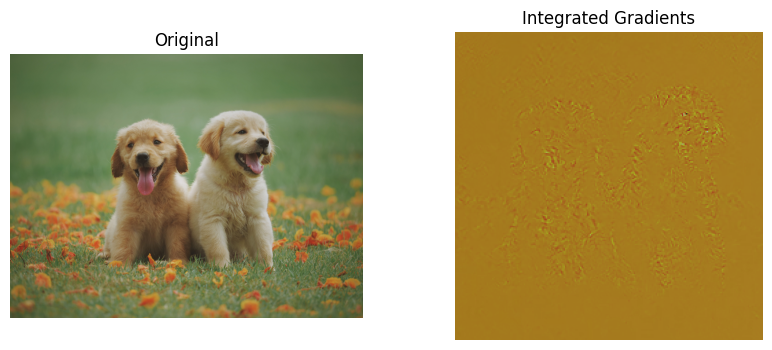

In [7]:
ig = IntegratedGradients(model)

baseline = torch.zeros_like(input_tensor).to(device)

attributions_ig = ig.attribute(
    input_tensor,
    baselines=baseline,
    target=target,
    n_steps=50
)

attr_ig = attributions_ig.squeeze().detach().cpu().numpy()

attr_ig = attr_ig.sum(axis=0)

attr_ig_norm = (attr_ig - attr_ig.min()) / (
    attr_ig.max() - attr_ig.min() + 1e-8
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_pil)
plt.imshow(attr_ig_norm, cmap="hot", alpha=0.5)
plt.title("Integrated Gradients")
plt.axis("off")

plt.show()

/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


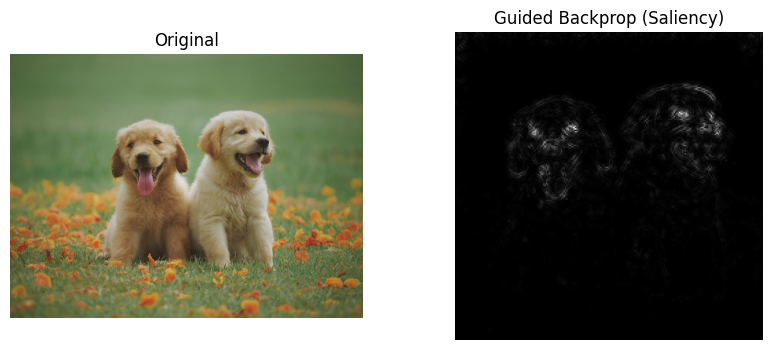

In [8]:
gbp = GuidedBackprop(model)

input_tensor.requires_grad = True

attributions_gbp = gbp.attribute(input_tensor, target=target)

attr_gbp = attributions_gbp.squeeze().detach().cpu().numpy()

attr_gbp = np.abs(attr_gbp).sum(axis=0)

attr_gbp_norm = (attr_gbp - attr_gbp.min()) / (
    attr_gbp.max() - attr_gbp.min() + 1e-8
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(attr_gbp_norm, cmap="gray")
plt.title("Guided Backprop (Saliency)")
plt.axis("off")

plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
model.to(device)
input_tensor = input_tensor.to(device)

target_layers = [model.layer4[-1]]

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

targets = [ClassifierOutputTarget(target)]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

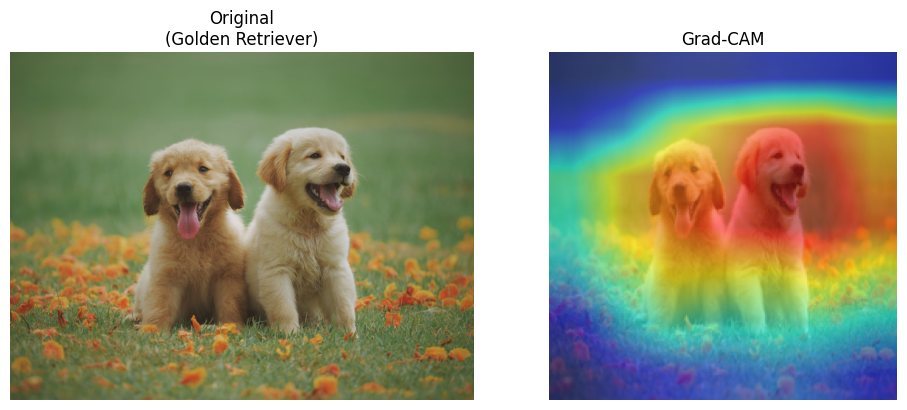

In [10]:
H_cam, W_cam = grayscale_cam.shape

img_resized = img_pil.resize((W_cam, H_cam))

rgb_img = np.array(img_resized).astype(np.float32) / 255.0

visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

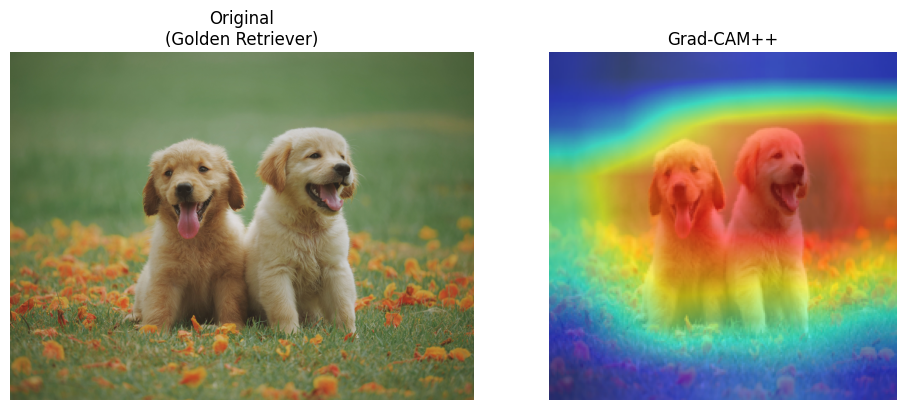

In [11]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
model.to(device)
input_tensor = input_tensor.to(device)

target_layers = [model.layer4[-1]]

cam_pp = GradCAMPlusPlus(
    model=model,
    target_layers=target_layers
)

targets = [ClassifierOutputTarget(target)]

grayscale_cam_pp = cam_pp(
    input_tensor=input_tensor,
    targets=targets
)[0]

H_cam, W_cam = grayscale_cam_pp.shape

img_resized_pp = img_pil.resize((W_cam, H_cam))

rgb_img_pp = np.array(img_resized_pp).astype(
    np.float32
) / 255.0

visualization_pp = show_cam_on_image(
    rgb_img_pp,
    grayscale_cam_pp,
    use_rgb=True
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization_pp)
plt.title("Grad-CAM++")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
def batch_predict(images):
    """
    images: list/array of images as float32 in [0,1]
    shape (H,W,3)
    returns: numpy array of probabilities
    """

    model.eval()
    batch_tensors = []

    for img in images:
        pil = Image.fromarray(
            (img * 255).astype(np.uint8)
        )

        t = preprocess(pil)
        batch_tensors.append(t)

    batch = torch.stack(batch_tensors).to(device)

    with torch.no_grad():
        logits = model(batch)
        probs = logits.softmax(dim=1)

    return probs.cpu().numpy()


img_lime = np.array(img_pil).astype(
    np.float32
) / 255.0

In [ ]:
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    img_lime,
    batch_predict,
    top_labels=5,
    hide_color=0,
    num_samples=20
)

lime_label = target

temp, mask = explanation.get_image_and_mask(
    lime_label,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME - important superpixels")
plt.axis("off")

plt.tight_layout()
plt.show()

  0%|          | 0/20 [00:00<?, ?it/s]